# Analyze trends/integrations in the final benchmark

In [87]:
import numpy as np
import pandas as pd
import scipy
from scipy.cluster.hierarchy import linkage, leaves_list
import seaborn as sns
import glob
import matplotlib.pyplot as plt
import scanpy as sc
import anndata as ad
from matplotlib.patches import Patch
from sklearn.decomposition import PCA

from bs4 import BeautifulSoup
import json
import colorcet as cc
import re

import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arialbd.ttf')
bold_prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arialbd.ttf')

In [88]:
import sys
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scripts/project_utils/')

from analysis_helpers import *

## scCRAFT default vs. new hyperparameters

Load the best hyperparameters for scCRAFT on the optimized data and propose new default hyperparameters.

In [89]:
rows = []
for d in glob.glob('../results/final_benchmark/sccraft_optuna/final/*'):
    with open(d + '/sccraftoptuna/best_params-1.json') as f:
        j = json.load(f)
        j['dataset'] = d.split('/')[-1]
        del j['trial_number']
        rows.append(j)

In [93]:
best_params = pd.DataFrame(rows)
best_params

,kl_coef,d_coef,z_dim,resolution1,resolution2,method,dataset
0,0.000124,0.491343,256,0.301577,8.632777,Leiden,villani_dcs
1,0.000479,0.373698,384,0.330681,9.318563,Louvain,mouse_hsc_prog
2,0.004630,0.383920,384,0.367148,8.333120,Leiden,haniffa_covid_2samples
3,0.003952,0.479464,128,0.262317,4.741523,Louvain,snpatho_liver
4,0.002062,0.290459,256,0.446586,9.487150,Louvain,haniffa_covid_imbalance
5,0.004171,0.476792,64,0.224938,4.238419,Leiden,human_liver
6,0.004853,0.486724,256,0.333726,8.980357,Leiden,human_dkd
7,0.000830,0.303285,64,0.200132,9.895027,Leiden,human_bipolar
8,0.002594,0.329141,128,0.696071,5.517359,Leiden,human_pancreas_full
9,0.002664,0.383173,384,0.254813,7.191226,Leiden,mouse_intestine


In [94]:
print(best_params['kl_coef'].mean())
print(best_params['d_coef'].mean())
print(best_params['z_dim'].mean())
print(best_params['resolution1'].mean())
print(best_params['resolution2'].mean())

0.002635938405236775
0.3997999028305281
230.4
0.34179897678730564
7.633552140075155


After running the new default hyperparameters, compare against the old defaults.

In [95]:
df = pd.read_csv('../results/final_benchmark/sccraft_new_hyperparams/metrics/all-metrics.csv')
df = df.pivot(index=['Dataset', 'Integration'], columns=['Metric'], values='Value').reset_index()
df['BIO'] = df[['BAMI', 'BRAS', 'ISOLISI', 'SCGRAPHM']].mean(axis=1, skipna=True)
df['BATCH'] = df[['CPCR', 'KBET', 'BRAS']].mean(axis=1, skipna=True)
df['OVERALL'] = df['BIO'] * .6 + df['BATCH'] * .4

In [96]:
df['Dataset'] = df['Dataset'].replace({
    'gtex_v9': 'GTEx v9',
    'human_kidney': 'Human kidney',
    'pan_cancer_t': "Pan-cancer T",
    'immune_cell_atlas': "Immune cell atlas",
    'tabula_sapiens': "Tabula sapiens",
    'mouse_pancreatic_islet': "Mouse pancreatic islet"
})

In [97]:
defaults = pd.read_csv('../results/spreadsheets/final_benchmark_new_data.csv')
defaults = defaults[defaults['Integration'] == 'sccraft-1']
defaults['Dataset'] = defaults['Dataset'].replace({
    'gtex_v9': 'GTEx v9',
    'human_kidney': 'Human kidney',
    'pan_cancer_t': "Pan-cancer T",
    'immune_cell_atlas': "Immune cell atlas",
    'tabula_sapiens': "Tabula sapiens",
    'mouse_pancreatic_islet': "Mouse pancreatic islet"
})
defaults = defaults.set_index('Dataset', drop=True).sort_index()
defaults = defaults.loc[['GTEx v9', 'Human kidney', 'Immune cell atlas', 'Pan-cancer T', 'Tabula sapiens', 'Mouse pancreatic islet']].sort_index()

In [98]:
optimized = df

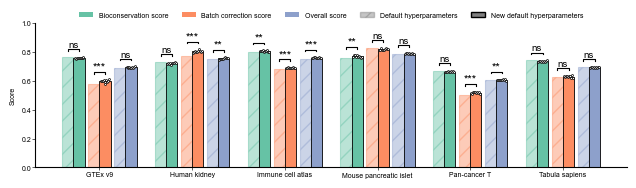

In [100]:
metrics = ["Bioconservation score", "Batch correction score", "Overall score"]
set2 = plt.get_cmap("Set2").colors
colors = {m: set2[k] for k, m in enumerate(metrics)}

def stars(p):
    if p < 0.001: return "***"
    if p < 0.01:  return "**"
    if p < 0.05:  return "*"
    return "ns"

dfl = defaults.reset_index() if "Dataset" not in defaults.columns else defaults
opt = optimized.reset_index() if "Dataset" not in optimized.columns else optimized
dfl = dfl.set_index("Dataset")

dfl.rename({
    'BIO': 'Bioconservation score',
    'BATCH': "Batch correction score",
    "OVERALL": "Overall score"
}, axis=1, inplace=True)

opt.rename({
    'BIO': 'Bioconservation score',
    'BATCH': "Batch correction score",
    "OVERALL": "Overall score"
}, axis=1, inplace=True)


datasets = list(dfl.index)
rng = np.random.default_rng(0)

bar_w = 0.12
pair_gap = 0.04
fig, ax = plt.subplots(figsize=(6.5, 2))
pvals = {}

for i, ds in enumerate(datasets):
    opt_ds = opt[opt["Dataset"] == ds]
    for j, m in enumerate(metrics):
        center = i + (j - 1) * (2 * bar_w + pair_gap)
        x_def, x_opt = center - bar_w / 2, center + bar_w / 2

        default_val = dfl.loc[ds, m]
        ax.bar(x_def, dfl.loc[ds, m], bar_w, color=colors[m], alpha=0.45,
               hatch="//", edgecolor=colors[m], linewidth=0.8)

        vals = opt_ds[m].values
        ax.bar(x_opt, vals.mean(), bar_w, color=colors[m], edgecolor="black", linewidth=0.6)
        offsets = np.linspace(-0.4 * bar_w, 0.4 * bar_w, len(vals))
        ax.scatter(x_opt + offsets, vals, s=2, color="white",
                   edgecolor="black", linewidth=0.5, zorder=3)
        
        t, p = scipy.stats.ttest_1samp(vals, popmean=default_val, alternative="greater")
        pvals[(ds, m)] = p

        y = max(default_val, vals.max()) + 0.04
        h = 0.012
        ax.plot([x_def, x_def, x_opt, x_opt], [y, y + h, y + h, y],
                color="black", linewidth=0.8)
        ax.text((x_def + x_opt) / 2, y + h, stars(p), ha="center", va="bottom",
                fontsize=8 if p < 0.05 else 7)

ax.set_xticks(range(len(datasets)))
ax.set_xticklabels(datasets, rotation=0)
ax.set_ylabel("Score", fontsize=5)
ax.set_ylim(0, 1)

legend = [Patch(facecolor=colors[m], label=m) for m in metrics]
legend += [
    Patch(facecolor="grey", alpha=0.45, hatch="//", edgecolor="grey", label="Default hyperparameters"),
    Patch(facecolor="grey", edgecolor="black", label="New default hyperparameters"),
]
ax.legend(handles=legend, ncol=5, loc="upper center",
          bbox_to_anchor=(0.5, 1.12), frameon=False, fontsize=5)
ax.tick_params(axis='both', which='major', width=.45, length=2, labelsize=5, pad=1)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig('../publication_figures/new_hyperparams_sccraft.svg')
plt.show()

## scVI default vs. new hyperparameters

Load the best hyperparameters for scVI on the optimized data and propose new default hyperparameters.

In [166]:
rows = []
for d in glob.glob('../results/final_benchmark/scvi_optuna/integration-models/*'):
    with open(d + '/scvioptuna/save_dir-1/best_params.json') as f:
        j = json.load(f)
        jj = j['best_params']
        jj['dataset'] = j['dataset']
        rows.append(jj)

In [167]:
best_params = pd.DataFrame(rows)
best_params

,n_latent,n_hidden,n_layers,dropout_rate,lr,dataset
0,28,256,1,0.159859,0.002345,villani_dcs.h5ad
1,61,256,2,0.048625,0.000892,mouse_hsc_prog.h5ad
2,61,256,3,0.167858,0.000322,human_pancreas_full.h5ad
3,50,256,2,0.023417,0.000445,haniffa_covid_2samples.h5ad
4,47,256,2,0.014070,0.000980,haniffa_covid_imbalance.h5ad
5,14,64,3,0.117086,0.003616,snpatho_liver.h5ad
6,60,256,1,0.025931,0.006175,human_liver.h5ad
7,63,256,2,0.086803,0.000262,human_bipolar.h5ad
8,58,256,3,0.019543,0.000765,human_dkd.h5ad
9,60,256,2,0.012643,0.000117,mouse_intestine.h5ad


In [168]:
print(best_params['n_latent'].mean())
print(best_params['n_layers'].mean())
print(best_params['dropout_rate'].mean())
print(best_params['lr'].mean())

50.2
2.1
0.06758354479513927
0.0015918894561184453


After running the new default hyperparameters, compare against the old defaults.

In [29]:
df = pd.concat([
    pd.read_csv('../results/final_benchmark/scvi_new_hyperparams/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/scvi_new_hyperparams_pancreatic_islet/metrics/all-metrics.csv')
])
df = df.pivot(index=['Dataset', 'Integration'], columns=['Metric'], values='Value').reset_index()
df['BIO'] = df[['BAMI', 'BRAS', 'ISOLISI', 'SCGRAPHM']].mean(axis=1, skipna=True)
df['BATCH'] = df[['CPCR', 'KBET', 'BRAS']].mean(axis=1, skipna=True)
df['OVERALL'] = df['BIO'] * .6 + df['BATCH'] * .4

In [30]:
df['Dataset'] = df['Dataset'].replace({
    'gtex_v9': 'GTEx v9',
    'human_kidney': 'Human kidney',
    'pan_cancer_t': "Pan-cancer T",
    'immune_cell_atlas': "Immune cell atlas",
    'tabula_sapiens': "Tabula sapiens",
    'mouse_pancreatic_islet': "Mouse pancreatic islet"
})

In [31]:
defaults = pd.read_csv('../results/spreadsheets/final_benchmark_new_data.csv')
defaults = defaults[defaults['Integration'] == 'scvi-1']
defaults['Dataset'] = defaults['Dataset'].replace({
    'gtex_v9': 'GTEx v9',
    'human_kidney': 'Human kidney',
    'pan_cancer_t': "Pan-cancer T",
    'immune_cell_atlas': "Immune cell atlas",
    'tabula_sapiens': "Tabula sapiens",
    'mouse_pancreatic_islet': "Mouse pancreatic islet"
})
defaults = defaults.set_index('Dataset', drop=True).sort_index()
defaults = defaults.loc[['GTEx v9', 'Human kidney', 'Immune cell atlas', 'Mouse pancreatic islet', 'Pan-cancer T', 'Tabula sapiens']]

In [33]:
optimized = df

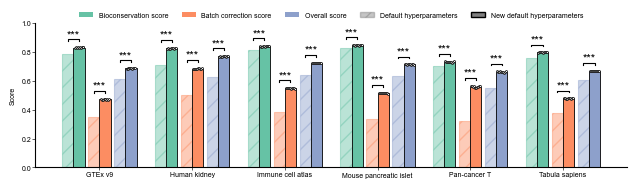

In [34]:
metrics = ["Bioconservation score", "Batch correction score", "Overall score"]
set2 = plt.get_cmap("Set2").colors
colors = {m: set2[k] for k, m in enumerate(metrics)}

def stars(p):
    if p < 0.001: return "***"
    if p < 0.01:  return "**"
    if p < 0.05:  return "*"
    return "ns"

dfl = defaults.reset_index() if "Dataset" not in defaults.columns else defaults
opt = optimized.reset_index() if "Dataset" not in optimized.columns else optimized
dfl = dfl.set_index("Dataset")

dfl.rename({
    'BIO': 'Bioconservation score',
    'BATCH': "Batch correction score",
    "OVERALL": "Overall score"
}, axis=1, inplace=True)

opt.rename({
    'BIO': 'Bioconservation score',
    'BATCH': "Batch correction score",
    "OVERALL": "Overall score"
}, axis=1, inplace=True)


datasets = list(dfl.index)
rng = np.random.default_rng(0)

bar_w = 0.12
pair_gap = 0.04
fig, ax = plt.subplots(figsize=(6.5, 2))
pvals = {}

for i, ds in enumerate(datasets):
    opt_ds = opt[opt["Dataset"] == ds]
    for j, m in enumerate(metrics):
        center = i + (j - 1) * (2 * bar_w + pair_gap)
        x_def, x_opt = center - bar_w / 2, center + bar_w / 2

        default_val = dfl.loc[ds, m]
        ax.bar(x_def, dfl.loc[ds, m], bar_w, color=colors[m], alpha=0.45,
               hatch="//", edgecolor=colors[m], linewidth=0.8)

        vals = opt_ds[m].values
        ax.bar(x_opt, vals.mean(), bar_w, color=colors[m], edgecolor="black", linewidth=0.6)
        offsets = np.linspace(-0.4 * bar_w, 0.4 * bar_w, len(vals))
        ax.scatter(x_opt + offsets, vals, s=2, color="white",
                   edgecolor="black", linewidth=0.5, zorder=3)
        
        t, p = scipy.stats.ttest_1samp(vals, popmean=default_val, alternative="greater")
        pvals[(ds, m)] = p

        y = max(default_val, vals.max()) + 0.04
        h = 0.012
        ax.plot([x_def, x_def, x_opt, x_opt], [y, y + h, y + h, y],
                color="black", linewidth=0.8)
        ax.text((x_def + x_opt) / 2, y + h, stars(p), ha="center", va="bottom",
                fontsize=8 if p < 0.05 else 7)

ax.set_xticks(range(len(datasets)))
ax.set_xticklabels(datasets, rotation=0)
ax.set_ylabel("Score", fontsize=5)
ax.set_ylim(0, 1)

legend = [Patch(facecolor=colors[m], label=m) for m in metrics]
legend += [
    Patch(facecolor="grey", alpha=0.45, hatch="//", edgecolor="grey", label="Default hyperparameters"),
    Patch(facecolor="grey", edgecolor="black", label="New default hyperparameters"),
]
ax.legend(handles=legend, ncol=5, loc="upper center",
          bbox_to_anchor=(0.5, 1.12), frameon=False, fontsize=5)
ax.tick_params(axis='both', which='major', width=.45, length=2, labelsize=5, pad=1)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig('../publication_figures/new_hyperparams_scvi.svg')
plt.show()

## Inspect specific integrations

In [101]:
from bs4 import BeautifulSoup
import json
import re

def load_html(file_path):
    with open(file_path, 'r') as f:
        html_content = f.read()

    soup = BeautifulSoup(html_content, 'html.parser')

    task_data = None
    for tag in soup.find_all('script'):
        text = tag.string
        if text and 'window.data =' in text:
            start = text.index('{', text.index('window.data ='))
            raw = text[start:]
            # Double any backslash that isn't part of a valid JSON escape
            raw = re.sub(r'\\(?!["\\/bfnrt]|u[0-9a-fA-F]{4})', r'\\\\', raw)
            task_data, _ = json.JSONDecoder(strict=False).raw_decode(raw)
            break

    if task_data and 'trace' in task_data:
        df = pd.DataFrame(task_data['trace'])
        return df[['name', 'workdir', 'status', 'peak_rss', 'duration']]
    print(f"Could not find task data in {file_path}.")
    return None

In [102]:
runs = pd.concat([
    load_html('../_nf-trace/final_benchmarking_cpu_methods/execution_report.html'),
    load_html('../_nf-trace/final_benchmarking_cpu_methods_gedi/execution_report.html'),
    load_html('../_nf-trace/final_benchmarking_cpu_methods_scalign/execution_report.html'),
    load_html('../_nf-trace/final_benchmarking_gpu_methods/execution_report.html'),
    load_html('../_nf-trace/final_benchmarking_gpu_methods_tabula/execution_report.html'),
    load_html('../_nf-trace/final_benchmarking_llm_methods/execution_report.html'),
    load_html('../_nf-trace/final_benchmarking_llm_methods_scprint/execution_report.html')
])

In [103]:
runs = runs[runs['name'].str.contains("INTEGRATE")]
runs['name'] = runs['name'].str[len('WF_ALL:INTEGRATION_FINAL:RUN_INTEGRATE_FINAL (RUN_INTEGRATE_'):-3]

In [104]:
runs['integration'] = runs['name'].str.split('_', n=1).str[0]
runs['dataset'] = runs['name'].str.split('_', n=1).str[1]

In [105]:
runs = runs[runs.status != 'FAILED']

In [30]:
runs.to_csv('../results/spreadsheets/final_benchmarking_runs.csv', index=False)

In [85]:
method = 'sysvi'
dataset = 'human_pancreas_full'
d = runs[runs.name.str.contains(dataset) & runs.name.str.contains(method)].iloc[0]['workdir']
print(d)
# adata_int = sc.read(f"{d}/save_dir/adata.h5ad")
adata_int = sc.read('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/work/final_benchmarking/sysvi_optuna/61/746f1cfe27307ab0af2aa7f286bdad/adata.h5ad')
sc.pp.neighbors(adata_int, use_rep='X_integration')
sc.tl.umap(adata_int)
batch_col = adata_int.obs.columns[0]
celltype_col = adata_int.obs.columns[-1]

# if adata_int.X is None:
#     adata_int = ad.AnnData(
#         X=adata.X,
#         obs=adata_int.obs,
#         var=adata.var,
#         uns=adata_int.uns,
#         obsm=adata_int.obsm,
#         varm=adata_int.varm,
#         obsp=adata_int.obsp,
#         varp=adata.varp,
#         layers=adata.layers,
# )
adata_int

/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/work/final_benchmarking/gpu_methods/c7/94a59c520784e192725af557b9effe


AnnData object with n_obs × n_vars = 39944 × 15149
    obs: 'tech', 'celltype'
    uns: 'neighbors', 'umap'
    obsm: 'X_integration', 'X_umap'
    obsp: 'connectivities', 'distances'

In [ ]:
sc.pl.umap(adata_int, color=[batch_col, celltype_col])

In [ ]:
a, b = 2,3
coords = np.asarray(adata_int.obsm['X_integration'])[:, [a-1, b-1]]

lo, hi = np.percentile(coords, [1, 99], axis=0)
pad = 0.05 * (hi - lo)
lo, hi = lo - pad, hi + pad

axes = sc.pl.embedding(
    adata_int, 'X_integration', components=[f'{a},{b}'],
    color=[batch_col, celltype_col],
    show=False,
    wspace=0.6,
)

for ax in axes:
    ax.set_xlim(lo[0], hi[0])
    ax.set_ylim(lo[1], hi[1])

plt.show()

In [43]:
adata_int.obsm['pca_2d'] = PCA(n_components=2).fit_transform(adata_int.obsm["X_integration"])

In [ ]:
sc.pl.embedding(adata_int, 'pca_2d', color=[batch_col, celltype_col])